# Étape 3 : Consolidation et Validation de l'Annotation Croisée
Ce dernier notebook de préparation vise à agréger les annotations réalisées par notre équipe d'annotateurs sur le grand échantillon. Nous allons calculer l'accord inter-juges (pour évaluer la qualité des annotations), traiter les cas de désaccord, et exporter le jeu de données final nettoyé.

In [1]:
import pandas as pd
import itertools
from functools import reduce
from sklearn.metrics import cohen_kappa_score
from rules import evaluer_algorithme

In [2]:
df_preproc = pd.read_csv("./data/df_preproc.csv")
df_preproc['text'] = df_preproc['text'].astype(str).str.strip()

df_1 = pd.read_csv("./data/annote/admin.csv")
df_2 = pd.read_csv("./data/annote/ihssane.csv")
df_3 = pd.read_csv("./data/annote/selene.csv")
df_4 = pd.read_csv("./data/annote/shima.csv")

In [3]:
dfs = {
    'anis': df_1,
    'ihssane': df_2,
    'selene': df_3,
    'shima': df_4
}

## 3.1 Chargement, Nettoyage et Réconciliation des Identifiants
Au cours du processus d'annotation, un décalage a été identifié entre la colonne `id` originale et les données traitées (utilisation par erreur du `local_id`). Nous reconstruisons ici l'identifiant complet (Spécialité + local_id sur 5 digits). Pour les rares cas où cette reconstruction échoue, nous utilisons le texte brut comme clé de jointure (`text_to_id`) pour rapatrier l'identifiant correct depuis la base mère `df_preproc`.

In [4]:
# Création d'un dictionnaire {texte_complet : vrai_id} à partir de df_preproc
dict_text_to_id = df_preproc.drop_duplicates(subset=['text']).set_index('text')['id'].to_dict()

for nom, df in dfs.items():

    # Remplace les espaces par des tirets et convertit en texte et force 5 chiffres ("22" -> "00022")
    df["id"] = df['specialty'].str.replace(' ', '-') + '-' + df['local_id'].astype(str).str.zfill(5) 
    
    df['text'] = df['text'].astype(str).str.strip()

    # Identification des lignes dont l'ID reconstruit n'existe pas dans df_preproc
    ids_valides = set(df_preproc['id'])
    mask_invalide = ~df['id'].isin(ids_valides)
    nb_invalides = mask_invalide.sum()
    print(f"df_{nom}")
    print(f"Lignes avec un ID calculé introuvable : {nb_invalides}")

    # Récupération via le texte 
    if nb_invalides > 0:
        # On remplace l'ID (uniquement pour les lignes en erreur) par celui trouvé grâce au dictionnaire
        df.loc[mask_invalide, 'id'] = df.loc[mask_invalide, 'text'].map(dict_text_to_id)

    # Nettoyage final : on garde uniquement les lignes qui ont un ID valide
    # (Si le texte n'a pas été trouvé le .map() a renvoyé NaN)
    mask_final_valide = df['id'].isin(ids_valides)
    df_final = df[mask_final_valide].copy()

    lignes_supprimees = len(df) - len(df_final)
    print(f"Lignes définitivement supprimées (introuvables via ID et via Texte) : {lignes_supprimees}")
    print(f"Taille finale de ton jeu de données annoté propre : {len(df_final)} \n")

df_anis
Lignes avec un ID calculé introuvable : 3
Lignes définitivement supprimées (introuvables via ID et via Texte) : 0
Taille finale de ton jeu de données annoté propre : 234 

df_ihssane
Lignes avec un ID calculé introuvable : 6
Lignes définitivement supprimées (introuvables via ID et via Texte) : 0
Taille finale de ton jeu de données annoté propre : 237 

df_selene
Lignes avec un ID calculé introuvable : 6
Lignes définitivement supprimées (introuvables via ID et via Texte) : 0
Taille finale de ton jeu de données annoté propre : 156 

df_shima
Lignes avec un ID calculé introuvable : 9
Lignes définitivement supprimées (introuvables via ID et via Texte) : 0
Taille finale de ton jeu de données annoté propre : 286 



In [5]:
counts_table = pd.DataFrame({name: df['label'].value_counts() for name, df in dfs.items()}).fillna(0).astype(int)
counts_table['Total'] = counts_table.sum(axis=1)

pct_table = pd.DataFrame({name: df['label'].value_counts(normalize=True) * 100 for name, df in dfs.items()}).fillna(0).round(1)

print("Comptage par classe")
display(counts_table)

print("Pourcentage par classe (%)")
display(pct_table)

Comptage par classe


,anis,ihssane,selene,shima,Total
label,,,,,
Non mentionné,75,131,77,142,425
Non-fumeur,71,48,32,56,207
Fumeur actuel,47,33,25,47,152
Ancien fumeur,40,25,22,41,128


Pourcentage par classe (%)


,anis,ihssane,selene,shima
label,,,,
Non mentionné,32.2,55.3,49.4,49.7
Non-fumeur,30.5,20.3,20.5,19.6
Fumeur actuel,20.2,13.9,16.0,16.4
Ancien fumeur,17.2,10.5,14.1,14.3


## 3.2 Statistiques d'Annotation et Accord Inter-Juges
Nous évaluons ici la fiabilité de l'annotation en calculant :
1. Le volume annoté par chaque participant (comptages et pourcentages par classe).
2. Le taux de recouvrement des documents (combien de documents ont été annotés par 1, 2, 3 ou 4 personnes).
3. L'accord exact et le **Coefficient de Kappa de Cohen** pour chaque paire d'annotateurs. 
4. Le taux d'unanimité global sur les documents partagés.

In [6]:
all_ids = pd.concat([df_1["id"], df_2["id"], df_3["id"], df_4["id"]])

id_counts = all_ids.value_counts()

summary_counts = id_counts.value_counts().sort_index(ascending=False)
overlap_summary = pd.DataFrame({
    "Nombre d'annotateur": summary_counts.index,
    "Nombre de documents": summary_counts.values
})

print("Détail des documents partagés")
display(overlap_summary)

Détail des documents partagés


,Nombre d'annotateur,Nombre de documents
0,3,26
1,2,262
2,1,311


In [7]:
# On isole uniquement l'ID et le label, et on renomme la colonne label au nom de l'annotateur
renamed_dfs = [
    df[['id', 'label']].drop_duplicates('id').rename(columns={'label': name})
    for name, df in dfs.items()
]

# Fusion complète (Outer join) sur l'ID
merged = reduce(lambda left, right: pd.merge(left, right, on='id', how='outer'), renamed_dfs)
annotateurs = list(dfs.keys())

stats_paires = []

for a1, a2 in itertools.combinations(annotateurs, 2):
    # Conserver uniquement les documents annotés par les deux annotateurs de la paire
    pair_df = merged.dropna(subset=[a1, a2])
    
    nb_communs = len(pair_df)
    if nb_communs > 0:
        # Accord absolu (pourcentage de fois où ils ont mis exactement le même label)
        accords_exacts = (pair_df[a1] == pair_df[a2]).sum()
        pourcentage_accord = (accords_exacts / nb_communs) * 100
        
        # Kappa de Cohen (mesure la fiabilité inter-annotateurs)
        kappa = cohen_kappa_score(pair_df[a1], pair_df[a2])
        
        stats_paires.append({
            'Annotateur 1': a1,
            'Annotateur 2': a2,
            'Docs Communs': nb_communs,
            'Accord Exact (%)': round(pourcentage_accord, 1),
            'Kappa de Cohen': round(kappa, 3)
        })

df_stats_paires = pd.DataFrame(stats_paires)

print("Statistiques d'accord par paire d'annotateurs")
display(df_stats_paires)

# Statistiques globales sur les documents partagés (2 annotateurs ou plus)
# Filtre pour ne garder que les lignes où au moins 2 annotateurs ont répondu
overlap = merged[merged[annotateurs].notna().sum(axis=1) >= 2].copy()

def check_unanimite(row):
    labels_presents = row.dropna().tolist()
    return len(set(labels_presents)) == 1

overlap['Unanimite'] = overlap[annotateurs].apply(check_unanimite, axis=1)

taux_unanimite = (overlap['Unanimite'].sum() / len(overlap)) * 100

print("\nStatistiques Globales (Documents avec >= 2 annotations)")
print(f"Nombre total de documents multi-annotés : {len(overlap)}")
print(f"Documents avec accord unanime de tous les annotateurs présents : {overlap['Unanimite'].sum()} ({taux_unanimite:.1f}%)")

Statistiques d'accord par paire d'annotateurs


,Annotateur 1,Annotateur 2,Docs Communs,Accord Exact (%),Kappa de Cohen
0,anis,ihssane,75,97.3,0.962
1,anis,selene,84,100.0,1.000
2,anis,shima,90,96.7,0.955
3,ihssane,selene,13,100.0,1.000
4,ihssane,shima,61,100.0,1.000
5,selene,shima,16,100.0,1.000



Statistiques Globales (Documents avec >= 2 annotations)
Nombre total de documents multi-annotés : 287
Documents avec accord unanime de tous les annotateurs présents : 282 (98.3%)


## 3.3 Traitement des Désaccords (Résolution des Conflits)
Bien que le taux d'unanimité soit exceptionnellement élevé (plus de 98%), quelques documents présentent des divergences (faux positifs/négatifs humains ou ambiguïté du texte médical). Nous isolons ces cas pour une revue manuelle. 

In [8]:
# On filtre le tableau 'overlap' pour garder les lignes sans Unanimité
documents_en_desaccord = overlap[~overlap['Unanimite']].copy()

# On supprime la colonne booléenne 'Unanimite' pour un affichage plus propre
documents_en_desaccord = documents_en_desaccord.drop(columns=['Unanimite'])

print(f"Nombre de documents en désaccord : {len(documents_en_desaccord)}")
display(documents_en_desaccord)

Nombre de documents en désaccord : 5


,id,anis,ihssane,selene,shima
91,CANCERO-ADULTE-00935,Fumeur actuel,Ancien fumeur,NaN,NaN
414,MEDECINE-INTERNE-00042,Fumeur actuel,Non mentionné,NaN,NaN
432,MEDECINE-INTERNE-00315,Non mentionné,NaN,NaN,Fumeur actuel
468,NEUROLOGIE-00236,Non-fumeur,NaN,NaN,Non mentionné
595,UROLOGIE-00237,Non-fumeur,NaN,NaN,Non mentionné


In [9]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

In [10]:
for index, row in documents_en_desaccord.iterrows():
    print(row["id"])
    print(df_preproc.loc[df_preproc["id"] == row["id"], "text"])

CANCERO-ADULTE-00935
872    Compte rendu de consultation d oncologie médicale Le 20 05 2025 Je vois ce jour en consultation Monsieur Oktay SALEUR né le 11 06 1974 après 6 cures de CARBOPLATINE 5FU PEMBROLIZUMAB pour la prise en charge d un carcinome épidermoïde de du sinus piriforme droit classé T3N2bMX inopérable sur envahissement carotidien extension à la base du crâne foramen jugulaire Antécédents Médicaux ACFA Diabète de type 2 insulinodépendant Hypertension artérielle Coronarographie normale vers 2000 Canal lombaire étroit remaniements dégénératifs discarthrosiques étagés avec ostéophytose corporéale étagée L1 S L3 14 L4 15 el L5 S1 lRM rachis 03 2018 Syndrome dépressif Varices des membres inférieurs Obésité modérée Chirurgicaux non Familiaux non Oncologiques Adénocarcinome bronchique TTF1 PDL1 60 K RAS G12F cT4N2M1 osseux et cérébral en rémission complète après 5 ans de traitement par PEMBROLIZUMAB Surveillance depuis 2024 Mode de vie Retraité de l éducation nationale à Paris Pas

Suite à cette revue, nous écartons les documents trop ambigus et conservons la bonne étiquette pour les autres erreurs :

1- CANCERO-ADULTE-00935 : Le patient a 62 ans et le CR cite "Tabagisme entre 12 et 62 ans environ 3 paquets jours Cumulé à plus de 100 PA " sans dire qu'il a été sevré 

2- MEDECINE-INTERNE-00042 : "Tabagisme actif estimé à 20 PA" donc fumeur actuel

3- MEDECINE-INTERNE-00315 : BPCO post-tabagique citée mais aucune mentioon explicite du sevrage 

4- NEUROLOGIE-00236 : "Pas de prise de toxique" donc non-fumeur

5- UROLOGIE-00237 : "Pas de consommation toxique" donc non-fumeur

Pour les cas 1 et 3, c'est ambigu. on les retire. 
Pour les cas 2, 4 et 5, on garde la bonne annotation.

In [11]:
pd.reset_option("display.max_colwidth")
pd.reset_option("display.max_rows")

In [12]:
ids_a_supprimer = [
    "CANCERO-ADULTE-00935",
    "MEDECINE-INTERNE-00315"
]

for annotateur, df in dfs.items():
    dfs[annotateur] = df[
        ~df["id"].isin(ids_a_supprimer)
    ].copy()


dfs["ihssane"] = dfs["ihssane"][
    ~dfs["ihssane"]["id"].isin(["MEDECINE-INTERNE-00042"])
].copy()

dfs["shima"] = dfs["shima"][
    ~dfs["shima"]["id"].isin([
        "NEUROLOGIE-00236",
        "UROLOGIE-00237"
    ])
].copy()

## 3.4 Évaluation finale des règles et Export du Jeu d'Entraînement
Une fois les conflits résolus, nous concaténons toutes les annotations valides, supprimons les éventuels doublons (`drop_duplicates`), et exécutons une dernière évaluation de nos algorithmes à base de règles sur les annotations validées.
Enfin, nous isolons strictement les variables nécessaires à la modélisation (`id`, `text`, `label`) et exportons notre jeu de données final : `annotated_ML_ready.csv`.

In [13]:
df_final = pd.concat(
    [df for df in dfs.values()],
    ignore_index=True
)

In [14]:
df_final.shape

(906, 13)

In [15]:
df_final = df_final.drop_duplicates()

In [16]:
df_final.shape

(598, 13)

In [17]:
df_final.info()

<class 'pandas.DataFrame'>
Index: 598 entries, 0 to 905
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  598 non-null    str    
 1   text                598 non-null    str    
 2   Column1             598 non-null    int64  
 3   local_id            598 non-null    str    
 4   specialty           598 non-null    str    
 5   type                598 non-null    str    
 6   header              598 non-null    str    
 7   word_count          598 non-null    int64  
 8   mention_tabac       598 non-null    bool   
 9   pred_regle_base     598 non-null    str    
 10  pred_regle_avancee  598 non-null    str    
 11  label               597 non-null    str    
 12  Comments            0 non-null      float64
dtypes: bool(1), float64(1), int64(2), str(9)
memory usage: 1.9 MB


In [18]:
df_final[df_final["label"].isna()]

,id,text,Column1,local_id,specialty,type,header,word_count,mention_tabac,pred_regle_base,pred_regle_avancee,label,Comments
2,CHIR-CARDIO-VASC-00101_2,Compte rendu opératoire de Chirurgie cardiaque...,1824,00101_2,CHIR.CARDIO-VASC.,CRO,Compte rendu opératoire de Chirurgie cardiaque,687,True,Ancien fumeur,Non mentionné,NaN,NaN


In [19]:
df_final.loc[2, "text"]

'Compte rendu opératoire de Chirurgie cardiaque Date de l intervention 12 01 25 Chirurgien Dr Andre Lavault Intervention Valvuloplastie et annuloplastie mitrale associée à l ablation de l auricule gauche sous CEC Abord chirurgical Sternotomie médiane Pas d adhérences péricardiques Épanchement péricardique de moyenne abondance citrin Bilan chirurgical Oreillettes et ventricule droit dilatés Installation de la circulation extra corporelle Après héparinisation réalisation des bourses aortiques pour canulations artérielles aortiques par canule artérielle Edwards 24Fr et canule de cardioplégie antérograde Canulation des veines caves inférieure et supérieure Exclusion des veines caves par un lacet Canulation aveugle du sinus coronaire Départ de la circulation extra corporelle Normothermie Arrêt cardiaque par injection intra aortique d une solution sanguine chaude hyperkaliémique avec clampage aortique partielle Clampage aortique et protection myocardique Cardioplégie au sang froid à 20°C Car

In [20]:
df_final.loc[2, "label"] = "Non mentionné"

In [21]:
df_final['label'] = df_final['label'].astype(str).str.strip()
df_final['pred_regle_base'] = df_final['pred_regle_base'].astype(str).str.strip()
df_final['pred_regle_avancee'] = df_final['pred_regle_avancee'].astype(str).str.strip()

classes = ["Fumeur actuel", "Ancien fumeur", "Non-fumeur", "Non mentionné"]

Règle de Base :
Coefficient de Kappa : 0.5450
Niveau d'accord (Landis & Koch) : Modéré

Rapport de classification
               precision    recall  f1-score   support

Fumeur actuel       0.37      0.53      0.44        92
Ancien fumeur       0.53      0.90      0.66        78
   Non-fumeur       1.00      0.14      0.25       126
Non mentionné       0.89      0.93      0.91       302

     accuracy                           0.70       598
    macro avg       0.70      0.63      0.56       598
 weighted avg       0.79      0.70      0.67       598



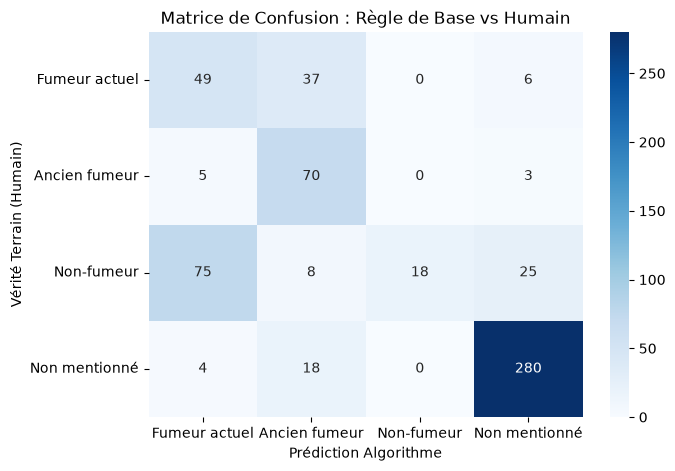

In [22]:
evaluer_algorithme(df_final['label'], df_final['pred_regle_base'], "Règle de Base", classes)

Règle Avancée :
Coefficient de Kappa : 0.8208
Niveau d'accord (Landis & Koch) : Presque parfait

Rapport de classification
               precision    recall  f1-score   support

Fumeur actuel       0.76      0.77      0.77        92
Ancien fumeur       0.81      0.82      0.82        78
   Non-fumeur       0.89      0.78      0.83       126
Non mentionné       0.93      0.98      0.95       302

     accuracy                           0.88       598
    macro avg       0.85      0.84      0.84       598
 weighted avg       0.88      0.88      0.88       598



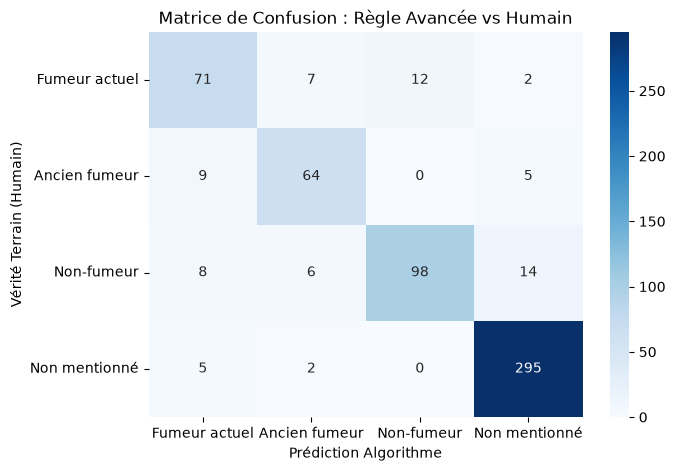

In [23]:
evaluer_algorithme(df_final['label'], df_final['pred_regle_avancee'], "Règle Avancée", classes)

In [24]:
df_final.columns

Index(['id', 'text', 'Column1', 'local_id', 'specialty', 'type', 'header',
       'word_count', 'mention_tabac', 'pred_regle_base', 'pred_regle_avancee',
       'label', 'Comments'],
      dtype='str')

In [25]:
df_final = df_final[["id", "text", "label"]]

In [26]:
df_final.set_index("id").to_csv("./data/annotated_corrected.csv", sep=",")